# Part 1 · Text processing and exploratory data analysis

This notebook goes with the Part 1 report (`reports/part-1/main.tex`), and its
sections follow the report's. Reusable code lives in the package:
`fashion_search.text` turns text into search terms and `fashion_search.corpus`
builds the product records. This notebook runs them, shows the evidence behind
each decision and saves the report's figures to `reports/part-1/figures/`.

Run `uv run python scripts/fetch_data.py` first, then run the notebook top to bottom.

In [1]:
import sys
import os

# Go up one level from 'notebooks' to the root directory, then into 'src'
src_path = os.path.abspath(os.path.join('..', 'src'))
if src_path not in sys.path:
    sys.path.append(src_path)

from fashion_search import corpus as cp

from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from fashion_search import corpus as cp
from fashion_search.text import build_terms, normalize_text

FIGURES = Path("../reports/part-1/figures")
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 80)

raw = cp.load_raw()
products = cp.build_corpus(raw)
labels = pd.read_csv("../data/validation_labels.csv")
QUERIES = {1: "women full sleeve sweatshirt cotton", 2: "men slim jeans blue"}
len(raw), len(products)

(28080, 28080)

## 2. Data preparation

### 2.1 Text pre-processing

`build_terms` applies the same steps to every text field and to queries:

1. **Repair and normalize**: undo UTF-8 text that was decoded as Latin-1
   (`â\x80\x99` back to `’`), fold accents and non-breaking spaces to plain ASCII, lowercase.
2. **Unify spelling variants**: `t-shirt`, `t shirt`, `tshirt`, `tee` → `tshirt`;
   `v-neck` → `vneck`; `slimfit` → `slim fit`.
3. **Remove possessives and join hyphenated words**: `women's` → `women`, `round-neck` → `roundneck`.
4. **Remove punctuation**: every other symbol becomes a space, so `cotton.Designed` splits in two.
5. **Tokenize** with NLTK's `word_tokenize`.
6. **Drop** stop words (NLTK English list), bare numbers and one-letter tokens.
7. **Stem** with the Porter stemmer, as in the practical labs.

In [2]:
examples = [
    "Women's Round-Neck T-Shirt",
    "Slimfit V neck tee",
    "Yorker trackpants made from 100% rich combed cotton.Designed for Comfort,Skin friendly",
    QUERIES[1],
    QUERIES[2],
]
pd.DataFrame({"text": examples, "terms": [build_terms(t) for t in examples]})

,text,terms
0,Women's Round-Neck T-Shirt,"[women, roundneck, tshirt]"
1,Slimfit V neck tee,"[slim, fit, vneck, tshirt]"
2,"Yorker trackpants made from 100% rich combed cotton.Designed for Comfort,Ski...","[yorker, trackpant, made, rich, comb, cotton, design, comfort, skin, friendli]"
3,women full sleeve sweatshirt cotton,"[women, full, sleev, sweatshirt, cotton]"
4,men slim jeans blue,"[men, slim, jean, blue]"


### 2.2 Fields kept for each result

Every result needs `pid, title, description, brand, category, sub_category,
product_details, seller, out_of_stock, selling_price, discount, actual_price,
average_rating, url`. They are all kept in their original form (numbers parsed,
see section 4) next to the term lists. How often each one is present:

In [3]:
present = {}
for field in cp.RESULT_FIELDS:
    col = products[field]
    if field == "product_details":
        present[field] = col.map(len).gt(0).mean()
    else:
        present[field] = col.notna().mean()
pd.Series(present, name="share present").round(3).to_frame()

,share present
pid,1.000
title,1.000
description,0.603
brand,0.928
category,1.000
sub_category,1.000
product_details,1.000
seller,0.941
out_of_stock,1.000
selling_price,1.000


### 2.3 Categorical fields: which to search, and how

Where do the words of the two validation queries appear, in the products
judged relevant? `details` is the values of `product_details` (without the
internal Style Code).

In [4]:
def field_text(row):
    return {
        "title": build_terms(row.title),
        "description": build_terms(row.description),
        "details": build_terms(cp.details_text(row.product_details)),
        "brand": build_terms(row.brand),
        "category": build_terms(f"{row.category} {row.sub_category}"),
    }

raw_by_pid = raw.set_index("pid")
rows = []
for qid, query in QUERIES.items():
    relevant = labels[(labels.query_id == qid) & (labels.labels == 1)].pid
    fields = [field_text(raw_by_pid.loc[p]) for p in relevant]
    for term in build_terms(query):
        for field in ["title", "description", "details", "brand", "category"]:
            share = sum(term in f[field] for f in fields) / len(fields)
            rows.append({"query": qid, "term": term, "field": field, "share": share})
coverage = pd.DataFrame(rows).pivot_table(index=["query", "term"], columns="field", values="share")
coverage = coverage[["title", "description", "details", "brand", "category"]]
coverage.round(2)

field             title  description  details  brand  category
query term                                                    
1     cotton        0.0         0.85     0.85    0.0       0.0
      full          1.0         0.46     1.00    0.0       0.0
      sleev         1.0         0.38     1.00    0.0       0.0
      sweatshirt    1.0         0.69     0.85    0.0       0.0
      women         1.0         0.46     0.31    0.0       0.0
2     blue          1.0         0.30     1.00    0.0       0.0
      jean          1.0         0.60     0.90    0.0       0.0
      men           0.7         0.00     0.70    0.0       0.0
      slim          0.5         0.50     0.10    0.0       0.0

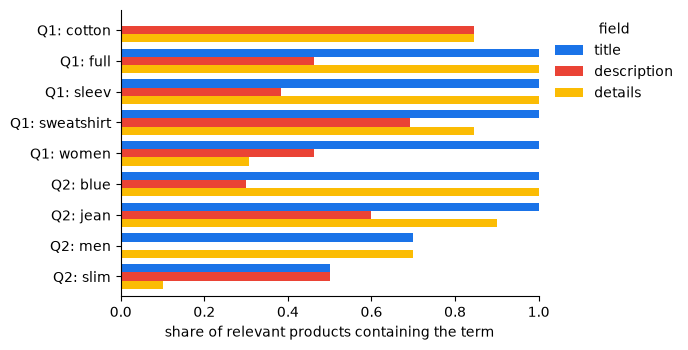

In [5]:
# Brand and category never contain a query term, so only the other three are plotted.
fig, ax = plt.subplots(figsize=(7, 3.6))
coverage[["title", "description", "details"]].plot.barh(ax=ax, width=0.8, color=["#1a73e8", "#ea4335", "#fbbc04"])
ax.invert_yaxis()
ax.set_xlabel("share of relevant products containing the term")
ax.set_ylabel("")
ax.set_yticklabels([f"Q{q}: {t}" for q, t in coverage.index])
ax.set_xlim(0, 1)
ax.legend(title="field", bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "query_terms_by_field.pdf")

With conjunctive (AND) queries a product only matches if **every** query term
is in its indexed text. How many relevant products each choice of fields can
still find:

In [6]:
schemes = {
    "title": ["title"],
    "title + description": ["title", "description"],
    "+ details": ["title", "description", "details"],
    "+ details + brand": ["title", "description", "details", "brand"],
    "+ details + brand + category": ["title", "description", "details", "brand", "category"],
}
rows = []
for qid, query in QUERIES.items():
    terms = set(build_terms(query))
    judged = labels[labels.query_id == qid]
    fields = {p: field_text(raw_by_pid.loc[p]) for p in judged.pid}
    for name, used in schemes.items():
        matched = {p for p, f in fields.items() if terms <= {t for u in used for t in f[u]}}
        rel = set(judged[judged.labels == 1].pid)
        rows.append({"query": qid, "fields": name,
                     "relevant matched": f"{len(matched & rel)}/{len(rel)}",
                     "non-relevant matched": f"{len(matched - rel)}/{len(judged) - len(rel)}"})
pd.DataFrame(rows).set_index(["query", "fields"])

relevant matched non-relevant matched
query fields                                                            
1     title                                    0/13                  0/7
      title + description                     11/13                  7/7
      + details                               13/13                  7/7
      + details + brand                       13/13                  7/7
      + details + brand + category            13/13                  7/7
2     title                                    4/10                 1/10
      title + description                      6/10                 2/10
      + details                                6/10                 2/10
      + details + brand                        6/10                 2/10
      + details + brand + category             6/10                 2/10

Category and sub-category never contain a query word and take very few values,
so they work better as filters than as searchable text:

In [7]:
pd.DataFrame({
    "distinct values": {f: products[f].nunique() for f in ["category", "sub_category", "brand", "seller"]},
    "most common share": {f: products[f].value_counts(normalize=True).iloc[0] for f in ["category", "sub_category", "brand", "seller"]},
}).round(3)

,distinct values,most common share
category,4,0.966
sub_category,24,0.545
brand,324,0.036
seller,534,0.053


### 2.4 Numerical fields

Prices, discount and rating arrive as text (`"2,999"`, `"69% off"`, `"3.9"`).
`parse_number` turns them into numbers, keeping missing values as missing
rather than zero. They are not indexed as terms: nobody searches for "921", and
they are more useful as filters and ranking signals.

In [8]:
numeric = ["selling_price", "actual_price", "discount", "average_rating"]
summary = products[numeric].describe().T[["count", "min", "50%", "max"]]
summary["missing"] = products[numeric].isna().sum()
summary.round(2)

,count,min,50%,max,missing
selling_price,28078.0,99.0,545.0,7999.0,2
actual_price,27303.0,150.0,1199.0,12999.0,777
discount,27225.0,1.0,53.0,87.0,855
average_rating,25819.0,1.0,3.8,5.0,2261


In [9]:
# Sanity checks: the parsed discount agrees with the two prices.
has_all = products.dropna(subset=["selling_price", "actual_price", "discount"])
implied = (1 - has_all.selling_price / has_all.actual_price) * 100
print("selling price above actual price:", int((has_all.selling_price > has_all.actual_price).sum()))
print("discount within 1 point of the prices:", round(((implied - has_all.discount).abs() <= 1).mean(), 3))

selling price above actual price: 0
discount within 1 point of the prices: 1.0


### 2.5 Output

The product records are written to `data/processed/products.parquet`
(`uv run python -m fashion_search.corpus` does the same from the command line).
Later parts, and the analysis below, read them with `cp.load_corpus()`.
Every validation product is present.

In [10]:
cp.save_corpus(products)
print("validation products found:", labels.pid.isin(products.pid).sum(), "/", len(labels))
pd.Series({f: len({t for ts in products[f"{f}_terms"] for t in ts}) for f in cp.TEXT_FIELDS}, name="vocabulary").to_frame()

validation products found: 40 / 40


,vocabulary
title,652
description,4933
details,3604
brand,388


## 3. Exploratory data analysis

What the catalogue looks like, and what that means for the search engine.
3.1 looks at the text the index is built from; 3.2 at the product fields that
act as filters and ranking signals. Every figure is saved to `reports/part-1/figures/`.

### 3.1 Text

Lengths are measured on the raw text (`raw`); vocabulary and frequencies on the
processed terms (`products`), which is what the index will contain.

In [11]:
import numpy as np
from collections import Counter

import spacy
from nltk.tokenize import sent_tokenize
from wordcloud import WordCloud

# en_core_web_sm is a project dependency, installed by `uv sync`.
nlp = spacy.load("en_core_web_sm")

# Read the records saved in 2.5, as the later parts will.
products = cp.load_corpus()

#### 3.1.1 Word-count distributions (raw text)

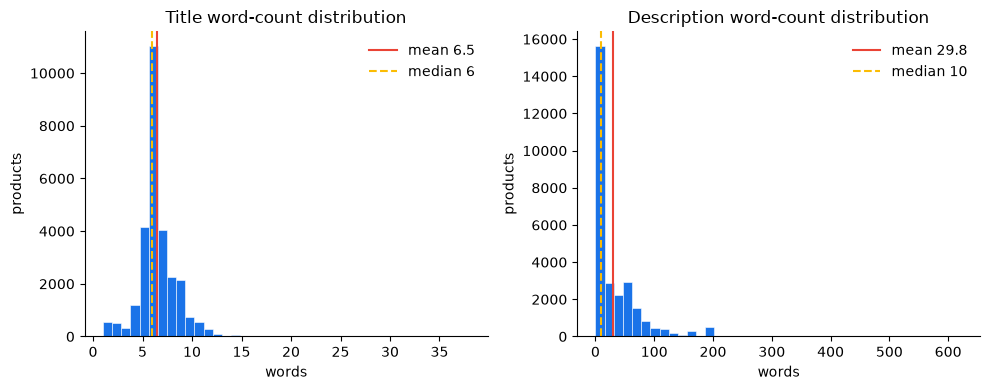

,Title,Description
count,28080.0,28080.0
mean,6.5,29.8
std,2.2,44.3
min,1.0,0.0
25%,6.0,0.0
50%,6.0,10.0
75%,7.0,49.0
max,38.0,623.0


In [12]:
title_wc = raw["title"].fillna("").str.split().str.len()
desc_wc  = raw["description"].fillna("").str.split().str.len()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, label in zip(axes,
                            [title_wc, desc_wc],
                            ["Title", "Description"]):
    ax.hist(data, bins=40, color="#1a73e8", edgecolor="white", linewidth=0.4)
    ax.axvline(data.mean(),   color="#ea4335", lw=1.5, label=f"mean {data.mean():.1f}")
    ax.axvline(data.median(), color="#fbbc04", lw=1.5, linestyle="--",
               label=f"median {data.median():.0f}")
    ax.set_title(f"{label} word-count distribution")
    ax.set_xlabel("words"); ax.set_ylabel("products")
    ax.legend(frameon=False)
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "word_count_distribution.pdf")
plt.show()

pd.DataFrame({"Title": title_wc.describe(), "Description": desc_wc.describe()}).round(1)

**Findings.** Titles are short and uniform: 6.5 words on average, and half of
them have 6 or 7. Descriptions vary a lot: 40% of products have none (the spike
at 0), which is why the median (10) is far below the mean (29.8); products that
do have one average about 49 words, with a tail up to 623. The title is the only
text every product has, so it is the field we can always rely on, and document
length will vary mostly because of the description.

#### 3.1.2 Average sentence length (descriptions)

In [13]:
descs = raw["description"].fillna("").str.strip()
descs = descs[descs != ""]
sents = descs.map(sent_tokenize)
words_per_sent = [len(s.split()) for ss in sents for s in ss]
print(f"sentences per description: mean {sents.map(len).mean():.1f}, median {sents.map(len).median():.0f}")
print(f"words per sentence: mean {np.mean(words_per_sent):.1f}, median {np.median(words_per_sent):.0f}")

sentences per description: mean 3.1, median 2
words per sentence: mean 15.7, median 14


**Findings.** Descriptions have 3.1 sentences of 15.7 words on average (medians
2 and 14): short marketing blurbs, not long text. Titles are noun phrases, not
sentences, so they are left out. The numbers are approximate: some descriptions
have no space after a full stop (`cotton.Designed`), which `sent_tokenize` does
not split, so a few pairs of sentences count as one.

#### 3.1.3 Vocabulary size before vs after pre-processing

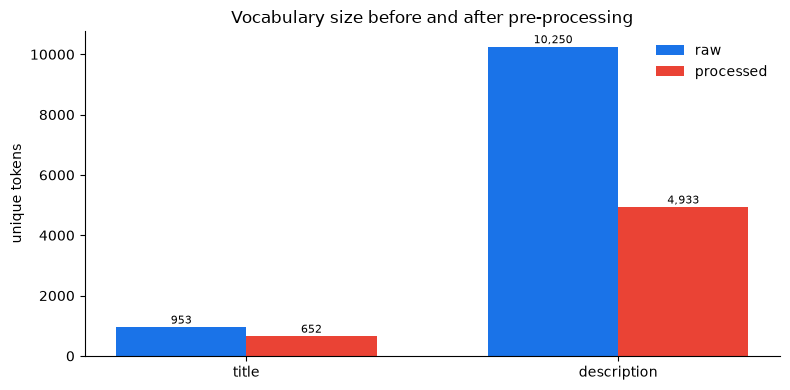

,field,stage,vocab
0,title,raw,953
1,description,raw,10250
2,title,processed,652
3,description,processed,4933
4,details,processed,3604
5,brand,processed,388


In [14]:
raw_title_vocab = {w.lower() for t in raw["title"].fillna("") for w in t.split()}
raw_desc_vocab  = {w.lower() for d in raw["description"].fillna("") for w in d.split()}
proc_title_vocab = {t for ts in products["title_terms"]       for t in ts}
proc_desc_vocab  = {t for ts in products["description_terms"] for t in ts}
proc_det_vocab   = {t for ts in products["details_terms"]     for t in ts}
proc_brand_vocab = {t for ts in products["brand_terms"]       for t in ts}

x, width = np.arange(2), 0.35
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(x - width/2, [len(raw_title_vocab), len(raw_desc_vocab)],  width, label="raw",       color="#1a73e8")
ax.bar(x + width/2, [len(proc_title_vocab), len(proc_desc_vocab)], width, label="processed", color="#ea4335")
ax.set_xticks(x); ax.set_xticklabels(["title", "description"])
ax.set_ylabel("unique tokens"); ax.set_title("Vocabulary size before and after pre-processing")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
for bar in ax.patches:
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 30,
            f"{int(bar.get_height()):,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
fig.savefig(FIGURES / "vocabulary_size.pdf")
plt.show()

pd.DataFrame({
    "field":  ["title", "description", "title", "description", "details", "brand"],
    "stage":  ["raw", "raw", "processed", "processed", "processed", "processed"],
    "vocab":  [len(raw_title_vocab), len(raw_desc_vocab),
               len(proc_title_vocab), len(proc_desc_vocab),
               len(proc_det_vocab), len(proc_brand_vocab)],
})

**Findings.** Pre-processing shrinks the title vocabulary by 32% (953 → 652)
and the description vocabulary by 52% (10,250 → 4,933). Part of the drop is
punctuation: the raw count only splits on spaces, so `cotton.` and `cotton,` are
separate words there. Titles use only about 650 terms across 28k products
because they follow a template (pattern, gender, neck, colour, garment:
*Printed Women Round Neck Black T-Shirt*), so many products have nearly
identical titles.

#### 3.1.4 Word clouds (processed terms)

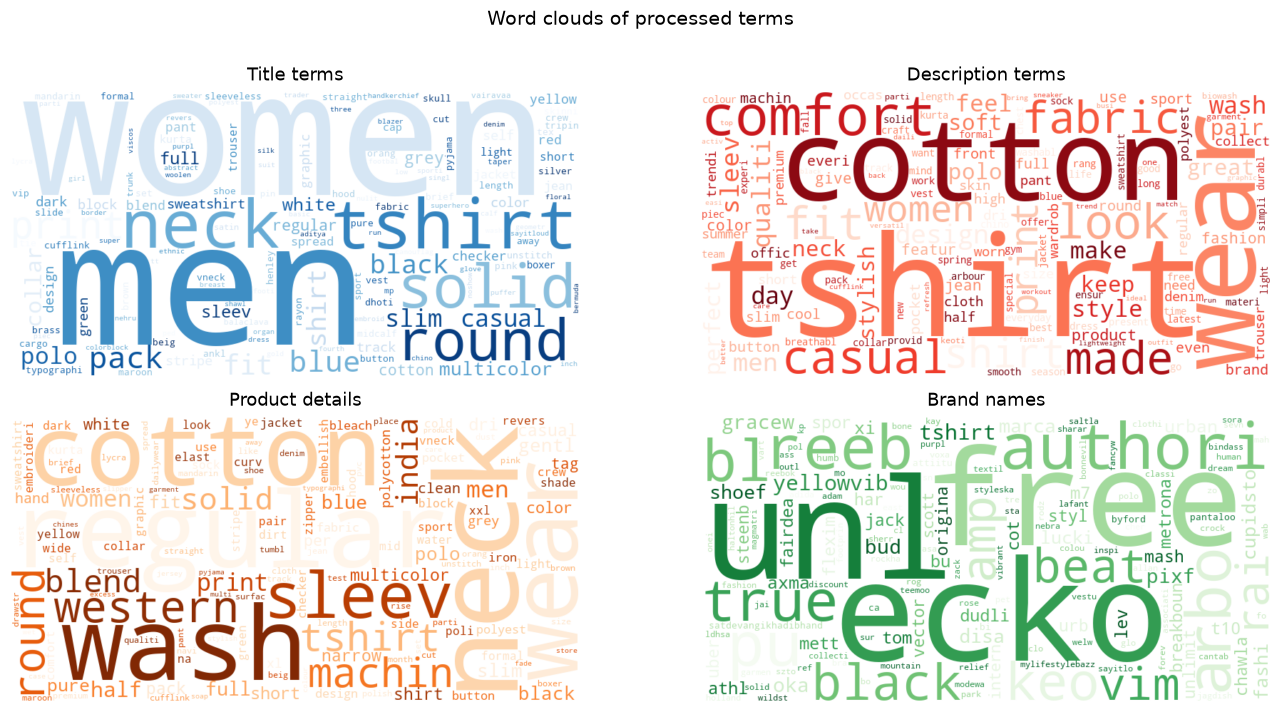

In [15]:
def make_wordcloud(terms_series, title, ax, colormap="Blues"):
    freq = Counter(t for ts in terms_series for t in ts)
    wc   = WordCloud(width=800, height=400, background_color="white",
                     colormap=colormap, max_words=150).generate_from_frequencies(freq)
    ax.imshow(wc, interpolation="bilinear"); ax.axis("off")
    ax.set_title(title, fontsize=13, pad=8)

fig, axes = plt.subplots(2, 2, figsize=(14, 7))
make_wordcloud(products["title_terms"],       "Title terms",       axes[0, 0], "Blues")
make_wordcloud(products["description_terms"], "Description terms", axes[0, 1], "Reds")
make_wordcloud(products["details_terms"],     "Product details",   axes[1, 0], "Oranges")
make_wordcloud(products["brand_terms"],       "Brand names",       axes[1, 1], "Greens")
fig.suptitle("Word clouds of processed terms", fontsize=14, y=1.01)
fig.tight_layout()
fig.savefig(FIGURES / "word_clouds.pdf", bbox_inches="tight")
plt.show()

**Findings.** Each field has its own vocabulary. Titles are garment, gender and
colour words (*tshirt*, *men*, *women*, *neck*, *round*, *solid*). Descriptions
add materials, but also many marketing words that say little about the product
(*comfort*, *look*, *wear*, *made*, *stylish*), a reason to weight descriptions
below titles. Details hold fabric, fit and care instructions (*cotton*,
*regular*, *wash*, *machin*). The brand cloud shows fragments such as *unl*,
*authori*, *bl* and *pu*, because brand names are truncated in the data (3.2.4).

#### 3.1.5 Top 50 most frequent terms

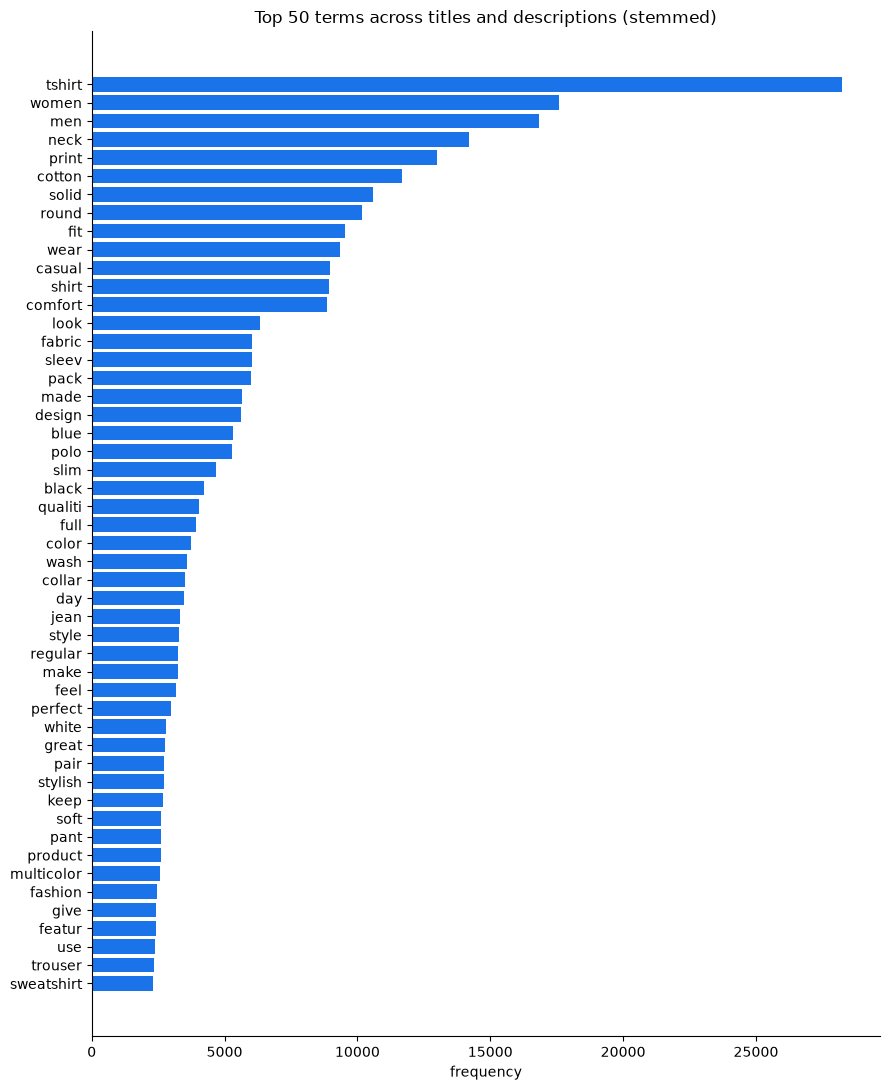

,term,count
0,tshirt,28256
1,women,17569
2,men,16831
3,neck,14191
4,print,13004
5,cotton,11694
6,solid,10595
7,round,10168
8,fit,9531
9,wear,9348


In [16]:
all_terms_freq = Counter(
    t for col in ["title_terms", "description_terms"]
    for ts in products[col] for t in ts
)
top50 = pd.DataFrame(all_terms_freq.most_common(50), columns=["term", "count"])

fig, ax = plt.subplots(figsize=(9, 11))
ax.barh(top50["term"][::-1], top50["count"][::-1], color="#1a73e8")
ax.set_xlabel("frequency")
ax.set_title("Top 50 terms across titles and descriptions (stemmed)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "top50_terms.pdf")
plt.show()
top50.head(20)

**Findings.** The catalogue is dominated by t-shirts: *tshirt* is the most
frequent term (28,256 occurrences), ahead of *women* (17,569) and *men*
(16,831). Several words of the validation queries are among the most frequent
terms (*women*, *men*, *cotton*, *sleev*, *blue*). They appear in so many
products that they barely tell them apart, so TF-IDF will give them a low weight
and rarer words such as *sweatshirt* or *jean* will drive the ranking. These are
occurrence counts; IDF uses the number of products that contain a term, which
Part 2 computes from the index.

#### 3.1.6 Named-entity recognition (spaCy)

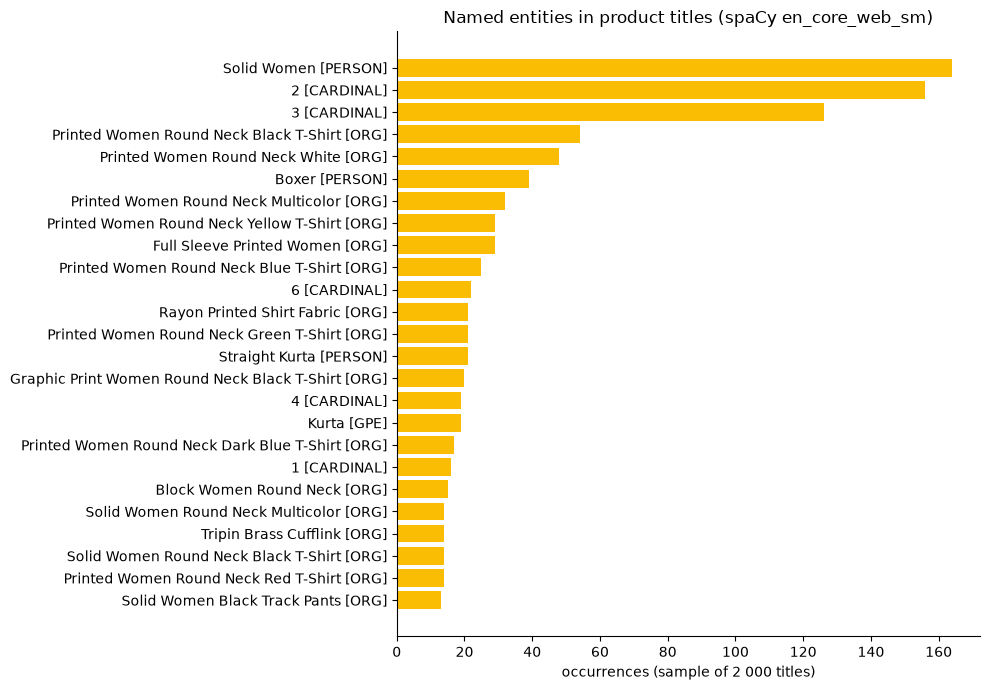

titles with at least one entity: 1402 / 2000


,occurrences,distinct
ORG,930,282
PERSON,421,93
CARDINAL,378,19
GPE,28,6
WORK_OF_ART,11,9
FAC,2,2
QUANTITY,1,1
PERCENT,1,1


In [17]:
sample_titles = raw["title"].dropna().sample(n=min(2000, len(raw)), random_state=42).tolist()
entity_counts = Counter()
for doc in nlp.pipe(sample_titles, batch_size=256, disable=["parser"]):
    for ent in doc.ents:
        entity_counts[(ent.label_, ent.text.title())] += 1

top_ents   = entity_counts.most_common(25)
ent_labels = [f"{e} [{l}]" for (l, e), _ in top_ents]
ent_counts = [c for _, c in top_ents]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(ent_labels[::-1], ent_counts[::-1], color="#fbbc04")
ax.set_xlabel("occurrences (sample of 2 000 titles)")
ax.set_title("Named entities in product titles (spaCy en_core_web_sm)")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(FIGURES / "named_entities.pdf")
plt.show()

# Entity type breakdown: occurrences and distinct strings per type.
occurrences, distinct = Counter(), Counter()
for (label, _), count in entity_counts.items():
    occurrences[label] += count
    distinct[label] += 1
print("titles with at least one entity:",
      sum(bool(doc.ents) for doc in nlp.pipe(sample_titles, batch_size=256, disable=["parser"])),
      "/", len(sample_titles))
pd.DataFrame({"occurrences": occurrences, "distinct": distinct}).sort_values("occurrences", ascending=False)

**Findings.** spaCy finds an entity in 1,402 of the 2,000 sampled titles (1,772
in total: ORG 930, PERSON 421, CARDINAL 378), but almost all are wrong: *Solid
Women* is tagged as a person, whole titles such as *Printed Women Round Neck
Black T-Shirt* as organisations, *Kurta* as a place, and the numbers are pack
sizes (*Pack of 2*). `en_core_web_sm` is trained on news text and reads
capitalised product titles as names. The real named entities of this catalogue,
the brands, already have their own field, so we do not use entity recognition
for indexing.

### 3.2 Catalogue

The product fields that are not searched as text: stock, prices, discount,
rating, sellers, brands and categories. Parsing and missing values are in 2.2
and 2.4; here we look at how the values are distributed, and what that means for
filtering and for our own ranking score in Part 3.

#### 3.2.1 Out-of-stock distribution

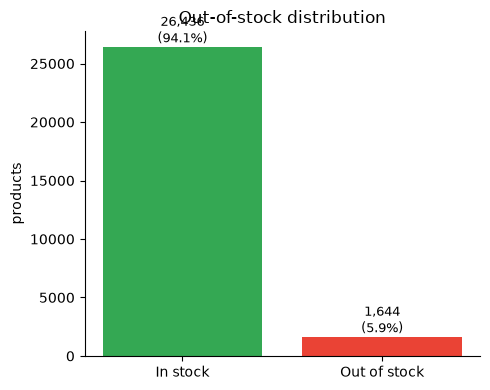

In [18]:
oos = products["out_of_stock"].value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["In stock", "Out of stock"], [oos.get(False, 0), oos.get(True, 0)],
       color=["#34a853", "#ea4335"])
for bar in ax.patches:
    pct = bar.get_height() / len(products) * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 20,
            f"{int(bar.get_height()):,}\n({pct:.1f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("products"); ax.set_title("Out-of-stock distribution")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIGURES / "out_of_stock.pdf"); plt.show()

**Findings.** Only 5.9% of products are out of stock. They are few, but nobody
can buy them, so they should not be ranked above available products: stock will
be a filter or a penalty in the ranking.

#### 3.2.2 Price and discount distributions

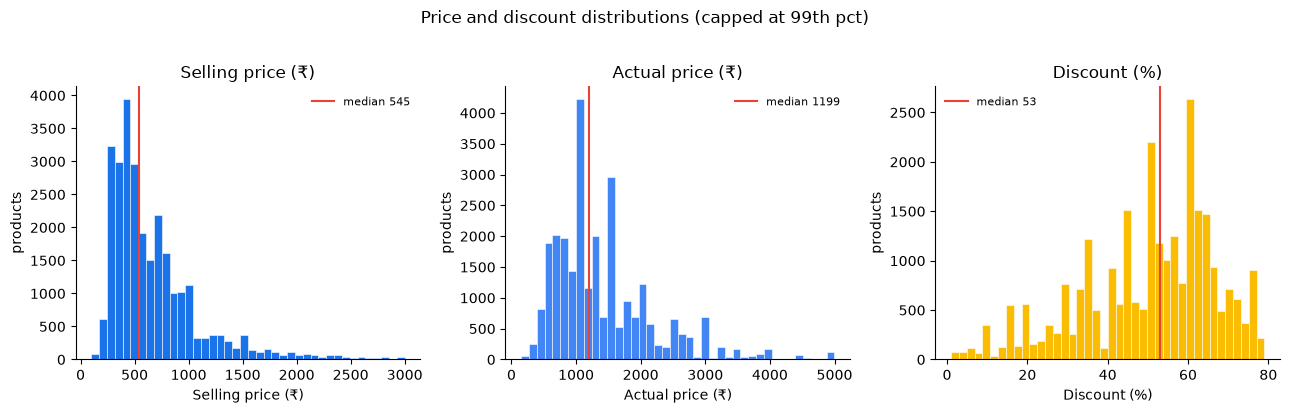

,selling_price,actual_price,discount
count,28078.0,27303.0,27225.0
mean,705.6,1455.5,50.3
std,549.7,940.0,16.9
min,99.0,150.0,1.0
25%,390.0,849.0,40.0
50%,545.0,1199.0,53.0
75%,820.0,1799.0,63.0
max,7999.0,12999.0,87.0


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, label, color in zip(
    axes,
    ["selling_price", "actual_price", "discount"],
    ["Selling price (₹)", "Actual price (₹)", "Discount (%)"],
    ["#1a73e8", "#4285f4", "#fbbc04"],
):
    data = products[col].dropna()
    cap  = data.quantile(0.99)          # cap outliers for readability
    ax.hist(data[data <= cap], bins=40, color=color, edgecolor="white", linewidth=0.4)
    ax.axvline(data.median(), color="#ea4335", lw=1.5, label=f"median {data.median():.0f}")
    ax.set_title(label); ax.set_xlabel(label); ax.set_ylabel("products")
    ax.legend(frameon=False, fontsize=8); ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Price and discount distributions (capped at 99th pct)", y=1.02)
fig.tight_layout(); fig.savefig(FIGURES / "price_distributions.pdf", bbox_inches="tight"); plt.show()
products[["selling_price","actual_price","discount"]].describe().round(1)

**Findings.** Prices are right-skewed: the median selling price is ₹545 (half
of products between ₹390 and ₹820) and the median actual price ₹1,199. Almost
every product is discounted, and heavily: median 53%, half between 40% and 63%,
up to 87%. The actual price works as a reference price; the selling price is
what the user pays, so it is the one to filter on. The plots leave out the top
1% so the tail does not squash the histograms.

#### 3.2.3 Average rating distribution

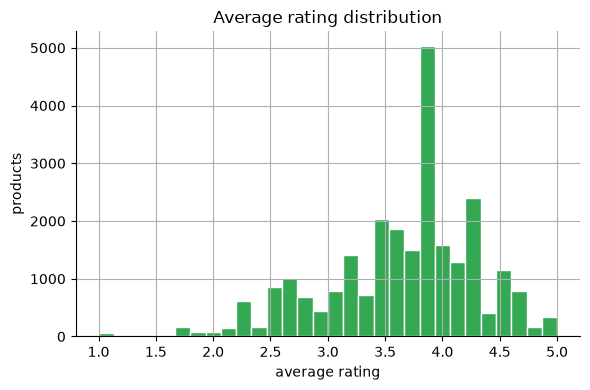

below 3: 16.8%   exactly 5.0: 1.3%   missing: 8.1%


,average_rating
count,25819.0
mean,3.63
std,0.66
min,1.0
25%,3.2
50%,3.8
75%,4.1
max,5.0


In [20]:
fig, ax = plt.subplots(figsize=(6, 4))
products["average_rating"].dropna().hist(bins=30, ax=ax, color="#34a853", edgecolor="white")
ax.set_xlabel("average rating"); ax.set_ylabel("products")
ax.set_title("Average rating distribution")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIGURES / "rating_distribution.pdf"); plt.show()
rating = products["average_rating"].dropna()
print(f"below 3: {(rating < 3).mean():.1%}   exactly 5.0: {(rating == 5).mean():.1%}   missing: {products['average_rating'].isna().mean():.1%}")
rating.describe().round(2).to_frame()

**Findings.** Ratings cluster between 3.2 and 4.1 (median 3.8); 16.8% of rated
products are below 3, only 1.3% have exactly 5.0, and 8.1% have no rating. The
dataset has no number of reviews, so a 5.0 from one review looks the same as a
5.0 from thousands. Missing ratings stay missing (not 0) when rating becomes
part of the score in Part 3.

#### 3.2.4 Top sellers and brands

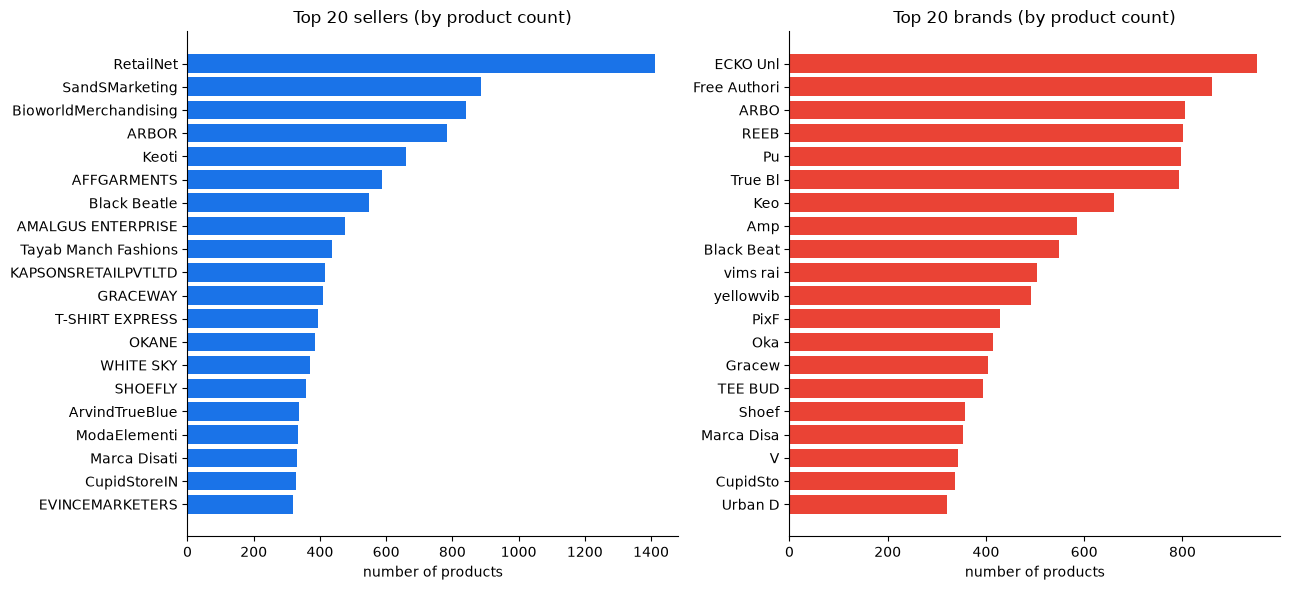

seller: 534 values, top 1 = 5.3%, top 20 = 40.1% of products with a seller
brand: 324 values, top 1 = 3.6%, top 20 = 42.8% of products with a brand


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
for ax, col, title, color in zip(
    axes,
    ["seller", "brand"],
    ["Top 20 sellers (by product count)", "Top 20 brands (by product count)"],
    ["#1a73e8", "#ea4335"],
):
    top = products[col].value_counts().head(20)
    ax.barh(top.index[::-1], top.values[::-1], color=color)
    ax.set_title(title); ax.set_xlabel("number of products")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIGURES / "top_sellers_brands.pdf"); plt.show()

for col in ["seller", "brand"]:
    counts = products[col].value_counts()
    print(f"{col}: {len(counts)} values, top 1 = {counts.iloc[0] / counts.sum():.1%}, "
          f"top 20 = {counts.head(20).sum() / counts.sum():.1%} of products with a {col}")

**Findings.** Both have a long tail: 534 sellers and 324 brands; the largest
seller (*RetailNet*) has 5.3% of products and the largest brand 3.6%, and the top
20 cover about 40% in both cases. Brand names are truncated in the source data
(*Pu*, *True Bl*, *ECKO Unl*, *V*), while seller names are complete
(*ArvindTrueBlue*). A query with a full brand name (*puma*) will not match the
brand field, so brand matches are less useful than the field's distinctiveness
suggests.

#### 3.2.5 Product rankings by rating, discount and price

In [22]:
display_cols = ["pid", "title", "brand"]

print("Top 10 by average rating")
display(products.nlargest(10, "average_rating")[display_cols + ["average_rating"]])

print("\nTop 10 most discounted")
display(products.nlargest(10, "discount")[display_cols + ["discount", "selling_price", "actual_price"]])

print("\nTop 10 most expensive (actual price)")
display(products.nlargest(10, "actual_price")[display_cols + ["actual_price"]])

Top 10 by average rating


,pid,title,brand,average_rating
411,SRTFHZ5V5CFUZQM5,Solid Women Red Chino Shorts,SayItLo,5.0
417,BXRFGYUGJCWWZ7UG,Printed Men Boxer (Pack of 1),SayItLo,5.0
443,BXRFKYKYF3SGUMFH,Printed Men Boxer (Pack of 1),SayItLo,5.0
456,TSHFKYKQQ9ZQF44K,Printed Women Round Neck White T-Shirt,SayItLo,5.0
781,ETHFSRVEN6JGSBYG,Men Kurta and Pyjama Set Cotton Blend,Jagdish Garmen,5.0
795,ETHFSRVEUG9Q4HTE,Women Kurta and Pyjama Set Cotton Blend,Jagdish Garmen,5.0
1160,TSHFVEHX5PURAVHT,Color Block Men Round Neck Multicolor T-Shirt,Clo,5.0
1860,JCKFVEVF6NNZHDSP,Sleeveless Solid Men Casual Jacket,REEB,5.0
1923,TKPFZ3JRDSRDZSEY,Self Design Women Black Track Pants,REEB,5.0
1974,TKPFZ3JRXCCAKDGD,Solid Men Black Track Pants,REEB,5.0



Top 10 most discounted


,pid,title,brand,discount,selling_price,actual_price
906,TSHF5FRXKGF6A4FH,Printed Women Round Neck White T-Shirt,Jack Roy,87.0,128.0,998.0
902,TSHFMFXGFJ7G2ABK,Printed Women Round Neck Grey T-Shirt,Jack Roy,86.0,136.0,999.0
903,TSHFMFT7VASAHBH3,Printed Women Round Neck White T-Shirt,Jack Roy,86.0,136.0,999.0
18249,TSHFGH6T3CVGDXS9,Printed Men Round Neck Multicolor T-Shirt (Pack of 2),yellowvib,85.0,449.0,2999.0
91,CTPFVZTBN4GRZKXH,nu-Lite Satin Tie & Cufflink (Red),NaN,84.0,499.0,3299.0
520,TSHEYQ73AFZZ4QHX,"Printed Women Round or Crew Black, Grey T-Shirt",Fairdea,84.0,201.0,1299.0
3102,TSHFVM4PQPRY2CRZ,Color Block Women Round Neck Green T-Shirt,REF,84.0,228.0,1499.0
9811,CAPE9YWMSVSZPM2K,Solid Balclava Cap,Gracew,84.0,228.0,1499.0
9813,CAPE9YWMURE4FKAJ,Solid Balclava Cap,Gracew,84.0,228.0,1499.0
18016,TSHFHQNCHJJUQYVQ,Printed Women Round Neck Blue T-Shirt,yellowvib,84.0,280.0,1800.0



Top 10 most expensive (actual price)


,pid,title,brand,actual_price
10272,SUIFNNPF3W8GEHAB,3 Piece Solid Women Suit,True Bl,12999.0
10287,SUIFPDS2DEZNSKTH,2 Piece Self Design Women Suit,True Bl,12999.0
10315,SUIFNMK2FQDWYTUZ,2 Piece Solid Men Suit,True Bl,12999.0
25423,JCKFQF5K72AT2JDC,Full Sleeve Solid Women Casual Jacket,Pu,12999.0
25815,JCKFQF5KMJJ349H8,Full Sleeve Solid Women Casual Jacket,Pu,12999.0
26089,SWSFUMFGQFKVZGYH,Full Sleeve Printed Men Sweatshirt,Pu,12999.0
6895,JEAF8S4GWU5YKQTF,Skinny Men Blue Jeans,G,12990.0
25569,JCKFW8EFUXMSBHMZ,Full Sleeve Solid Men Padded Jacket,Pu,10999.0
6870,JCKF8SWBNSGY5TPX,Full Sleeve Self Design Women Casual Jacket,G,10990.0
6898,JEAF8S4GE8PKH7H3,Regular Fit Men Dark Blue Cotton Blend Trousers,G,10990.0


**Findings.** No single field gives a useful ranking. The top 10 by rating are
all ties at 5.0, so their order is arbitrary (here, dataset order). The most
discounted products are cheap t-shirts at 84–87% off (₹128 instead of ₹998),
and the most expensive are suits and jackets at ₹12,999. Rating, discount and
price are useful as signals on top of text relevance, which is how Part 3 will
use them, but not as rankings by themselves.

#### 3.2.6 Category and sub-category breakdown

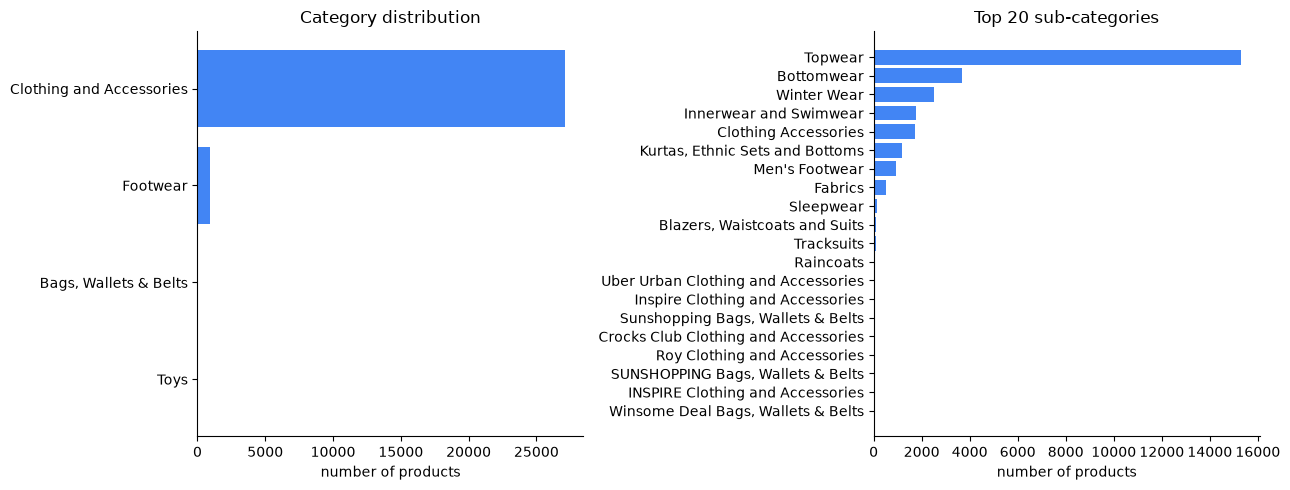

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, col, title in zip(
    axes,
    ["category", "sub_category"],
    ["Category distribution", "Top 20 sub-categories"],
):
    top = products[col].value_counts().head(20)
    ax.barh(top.index[::-1], top.values[::-1], color="#4285f4")
    ax.set_title(title); ax.set_xlabel("number of products")
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(FIGURES / "category_breakdown.pdf"); plt.show()

**Findings.** 96.6% of products are *Clothing and Accessories*; the rest are
almost all *Footwear*, with a handful of *Bags, Wallets & Belts* and *Toys*.
*Topwear* alone has 54.5% of products. Some sub-category values are noisy: a
brand glued to a category (*Uber Urban Clothing and Accessories*) or the same
value in two spellings (*SUNSHOPPING* and *Sunshopping Bags, Wallets & Belts*).
They are rare, but a sub-category filter should at least ignore case. With so
few and such unbalanced values, category works as a filter and would add almost
nothing as text (2.3).

## 4. Conclusions

A summary of the decisions (section 2) and the findings (section 3), computed
from the variables above.

In [24]:
pct_t    = (1 - len(proc_title_vocab) / len(raw_title_vocab)) * 100
pct_d    = (1 - len(proc_desc_vocab)  / len(raw_desc_vocab))  * 100
n_cat    = products["category"].nunique()
n_sub    = products["sub_category"].nunique()
miss_r   = products["average_rating"].isna().mean() * 100
oos_pct  = products["out_of_stock"].mean() * 100

print(f"""
TEXT PRE-PROCESSING
───────────────────
The pipeline (encoding repair → spelling normalisation → punctuation removal
→ tokenisation → stop-word removal → Porter stemming) reduces the title
vocabulary from {len(raw_title_vocab):,} to {len(proc_title_vocab):,} unique tokens (−{pct_t:.0f}%)
and the description vocabulary from {len(raw_desc_vocab):,} to {len(proc_desc_vocab):,} (−{pct_d:.0f}%).
Spelling unification (tshirt, vneck …) and possessive stripping let query and
document spellings of the same word match.

FIELD INDEXING STRATEGY
────────────────────────
• title, description, product_details, brand → indexed as separate term lists.
  With title, description and details, all 13 relevant products of query 1
  contain every query term (11 without details). Query 2 tops out at 6/10
  whatever the fields, since 4 relevant jeans never say "slim" (§2.3).
  Keeping the fields separate lets the ranking weight each one differently.

• category, sub_category → filter / facet fields only ({n_cat} and {n_sub} distinct
  values respectively). They never contain a raw query word, so including them
  in the inverted index would inflate postings without improving recall.

• seller → stored for display, not indexed. Queries are about products,
  not merchants.

NUMERICAL FIELDS
────────────────
selling_price, actual_price, discount and average_rating are parsed into
floats. They are NOT indexed as text: numeric range filters and ranking-score
boosts are more appropriate uses. {miss_r:.1f}% of products lack a rating.

DATASET HIGHLIGHTS
──────────────────
• {len(products):,} products across {n_cat} categories and {n_sub} sub-categories.
• Median title {title_wc.median():.0f} words; median description {desc_wc.median():.0f} words
  (long tail up to {desc_wc.max()} words).
• {oos_pct:.1f}% of products are currently out of stock.
• Median selling price ₹{products['selling_price'].median():.0f};
  median discount {products['discount'].median():.0f}%.
• Ratings centre around {products['average_rating'].median():.1f}/5;
  {(rating < 3).mean():.0%} of rated products are below 3.
• Sellers and brands have a long tail: no single one has more than about 5%
  of the products, and many brand names are truncated ("Pu", "True Bl").
""")


TEXT PRE-PROCESSING
───────────────────
The pipeline (encoding repair → spelling normalisation → punctuation removal
→ tokenisation → stop-word removal → Porter stemming) reduces the title
vocabulary from 953 to 652 unique tokens (−32%)
and the description vocabulary from 10,250 to 4,933 (−52%).
Spelling unification (tshirt, vneck …) and possessive stripping let query and
document spellings of the same word match.

FIELD INDEXING STRATEGY
────────────────────────
• title, description, product_details, brand → indexed as separate term lists.
  With title, description and details, all 13 relevant products of query 1
  contain every query term (11 without details). Query 2 tops out at 6/10
  whatever the fields, since 4 relevant jeans never say "slim" (§2.3).
  Keeping the fields separate lets the ranking weight each one differently.

• category, sub_category → filter / facet fields only (4 and 24 distinct
  values respectively). They never contain a raw query word, so including them
  i